<a href="https://colab.research.google.com/github/alexlimatds/esp_introducao_am/blob/main/estudo_de_caso_wine_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise de Desempenho de Classificadores no Dataset Wine Quality

Este notebook tem como objetivo avaliar o desempenho de diversos classificadores no dataset **Wine Quality** (disponível no [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/186/wine+quality)).

## Sobre o Dataset
O dataset é composto por amostras de vinhos tintos (*red*) e brancos (*white*) do norte de Portugal (vinho verde). O objetivo principal costuma ser modelar a qualidade do vinho com base em testes físico-químicos.

### Principais Características:
* **Instâncias:** 6.497 amostras no total.
* **Atributos de Entrada (Preditores Físico-Químicos):**
  1. **fixed acidity** (acidez fixa)
  2. **volatile acidity** (acidez volátil)
  3. **citric acid** (ácido cítrico)
  4. **residual sugar** (açúcar residual)
  5. **chlorides** (cloretos)
  6. **free sulfur dioxide** (dióxido de enxofre livre)
  7. **total sulfur dioxide** (dióxido de enxofre total)
  8. **density** (densidade)
  9. **pH**
  10. **sulphates** (sulfatos)
  11. **alcohol** (teor alcoólico)
* **Atributo Alvo (Target):**
  * **quality** (qualidade): Uma nota sensorial entre 0 e 10 atribuída por especialistas.
* **Atributo Adicional:**
  * **color** (cor): Indica se o vinho é tinto (*red*) ou branco (*white*).

## Objetivo do Notebook
Neste ambiente, realizamos o carregamento dos dados diretamente da API do UCI, analisamos a distribuição dos atributos e avaliamos diferentes algoritmos de classificação — como **K-Neighbors Classifier (KNN)**, **Nearest Centroid**, **Decision Trees** e classificadores de baseline (**Dummy Classifier**). Avaliamos também o impacto de técnicas de pré-processamento, como a **Padronização (StandardScaler)** e a **Normalização (MinMaxScaler)**, utilizando validação cruzada para garantir a robustez dos resultados.

## Carregando o dataset

In [1]:
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
uci_dataset = fetch_ucirepo(id=186)

# data (as pandas dataframes)
X = uci_dataset.data.features
y = uci_dataset.data.targets

## Análise dos atributos preditivos

In [3]:
# metadata
print("== Descrição dos atributos == ")
print(uci_dataset.metadata.additional_info.variable_info)
print(uci_dataset.variables)

== Descrição dos atributos == 
For more information, read [Cortez et al., 2009].
Input variables (based on physicochemical tests):
   1 - fixed acidity
   2 - volatile acidity
   3 - citric acid
   4 - residual sugar
   5 - chlorides
   6 - free sulfur dioxide
   7 - total sulfur dioxide
   8 - density
   9 - pH
   10 - sulphates
   11 - alcohol
Output variable (based on sensory data): 
   12 - quality (score between 0 and 10)
                    name     role         type demographic  \
0          fixed_acidity  Feature   Continuous        None   
1       volatile_acidity  Feature   Continuous        None   
2            citric_acid  Feature   Continuous        None   
3         residual_sugar  Feature   Continuous        None   
4              chlorides  Feature   Continuous        None   
5    free_sulfur_dioxide  Feature   Continuous        None   
6   total_sulfur_dioxide  Feature   Continuous        None   
7                density  Feature   Continuous        None   
8          

In [4]:
# Verificando que o atributo color não está presente no dataset
print('\nAtributo "color" está presente? R:',  'color' in X.columns)


Atributo "color" está presente? R: False


In [5]:
print(X.info())
display(X.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
dtypes: float64(11)
memory usage: 558.5 KB
None


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000


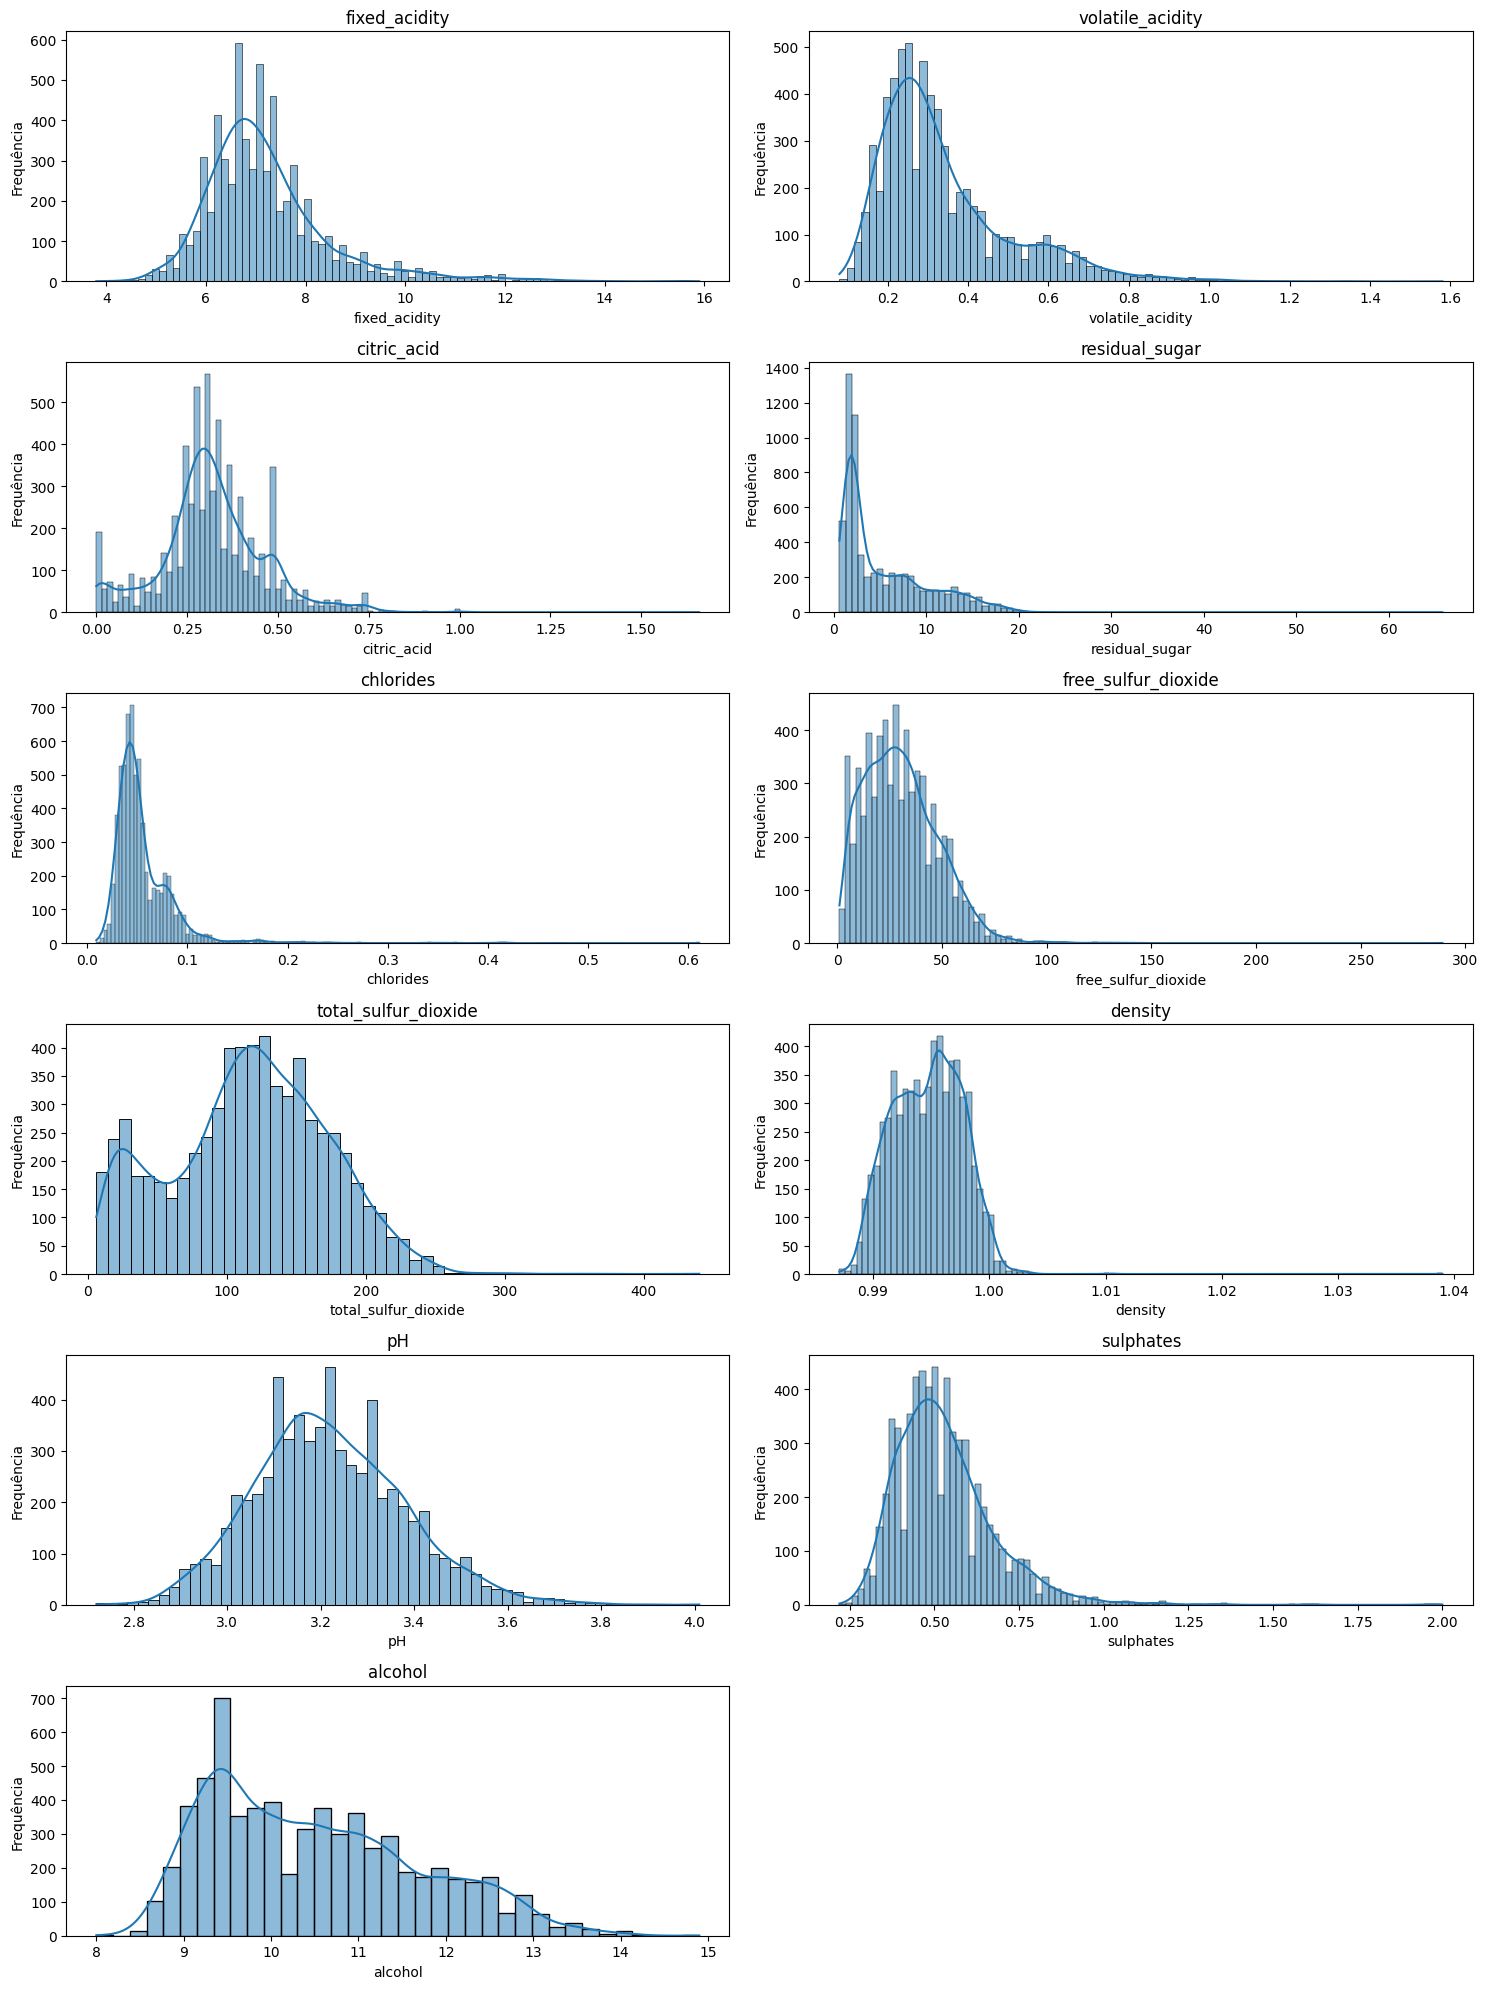

In [6]:
# Gerando gráficos de histogramas dos atributos para verificar suas
# distribuições de valores
import matplotlib.pyplot as plt
import seaborn as sns

def plot_histograms(data):
    plt.figure(figsize=(15, 20))
    for i, feature in enumerate(data.columns):
        plt.subplot(6, 2, i + 1) # 6 linhas, 2 colunas
        sns.histplot(data[feature], kde=True)
        # kde=True gera uma linha suave da distribuição de dados.
        # É útil para visualizar tendências
        plt.title(f'{feature}')
        plt.xlabel(feature)
        plt.ylabel('Frequência')
    plt.tight_layout() # Ajusta o layout para evitar sobreposição
    plt.show()

plot_histograms(X)

## Analisando o atributo alvo

In [7]:
# Informações sobre o atributo alvo
print('== ATRIBUTO ALVO ==')
print('\nValores para o atributo alvo:', y.quality.unique())
print('Quantidade de instâncias por cada valor do atributo:')
print(y.groupby('quality').size())

== ATRIBUTO ALVO ==

Valores para o atributo alvo: [5 6 7 4 8 3 9]
Quantidade de instâncias por cada valor do atributo:
quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
dtype: int64


## Função de avaliação de modelos

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn import tree, clone
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, precision_score
import pandas as pd

random_state = 42
scores_modelos = {} # chave: nome do modelo, valor: médias de precisão, recall e F1 obtidas por validação cruzada
y_np = y['quality'] # converte para um objeto Series

# Definindo um scorer personalizado para lidar com a divisão por zero
precision_scorer = make_scorer(
    precision_score,
    average='macro',
    zero_division=0   # controle do comportamento (0, 1.0 ou 'warn')
)
scoring = {
    'accuracy': 'accuracy',
    'precision': precision_scorer,
    'recall': 'recall_macro',
    'f1': 'f1_macro'
}

def validacao_cruzada(classificadores, X, y):
    medias = {}
    for nome, c in classificadores: # itera os modelos
        cv_results = cross_validate(
            c,
            X,
            y,
            cv=5,  # quantidade de partições,
            error_score=0,
            scoring=scoring
        )
        medias_sr = pd.DataFrame(cv_results).mean() # médias das colunas
        scores_modelos[nome] = medias_sr


## Modelos sem normalização ou padronização

In [9]:
# Avaliação sem normalização ou padronização
modelos = [
    ('Dummy', DummyClassifier(random_state=random_state)),
    ('Centróides', NearestCentroid()),
    ('3-NN', KNeighborsClassifier(n_neighbors=3)),
    ('5-NN', KNeighborsClassifier(n_neighbors=3)),
    ('9-NN', KNeighborsClassifier(n_neighbors=3)),
    ('Árvore de decisão', tree.DecisionTreeClassifier(random_state=random_state)),
    ('Árvore de decisão com restrição', tree.DecisionTreeClassifier(max_depth=15, random_state=random_state))
]

validacao_cruzada(modelos, X, y_np)

## Entendendo o `Pipeline` do Scikit-Learn

No desenvolvimento de modelos de Machine Learning, é muito comum aplicar uma sequência de transformações nos dados (como tratamento de valores ausentes, normalização ou padronização) antes de enviá-los ao classificador final.

O objeto **`Pipeline`** do scikit-learn serve exatamente para encapsular e automatizar essa sequência de passos de forma limpa e segura.

### Vantagens do uso do Pipeline:
1. **Praticidade e Organização**: Agrupa todo o fluxo de trabalho (pré-processamento + modelagem) em um único objeto de código.
2. **Prevenção de Vazamento de Dados (*Data Leakage*)**: Garante que parâmetros de pré-processamento (como a média e o desvio padrão obtidos do conjunto de treino) sejam aplicados corretamente no conjunto de teste ou validação, sem que informações do teste vazem para o treino.
3. **Compatibilidade Automatizada**: Facilita imensamente o uso de técnicas como validação cruzada (`cross_validate`) e busca de hiperparâmetros (`GridSearchCV`), pois todo o pipeline é reajustado a cada partição (*fold*).

### Como funciona por trás dos panos?
Um pipeline é composto por uma lista de tuplas contendo `('nome_do_passo', estimador)`.
* Todos os passos intermediários devem ser **transformadores** (ou seja, devem implementar os métodos `fit` e `transform`).
* O passo final deve ser um **estimador/classificador** (que implementa `fit` e `predict`).

Quando chamamos `pipeline.fit(X, y)`:
1. O pipeline executa `fit_transform` sequencialmente nos dados de entrada por meio de todos os passos intermediários.
2. O classificador final é treinado (`fit`) com os dados totalmente transformados.

Quando chamamos `pipeline.predict(X)`:
1. Os dados de teste passam sequencialmente pela transformação (`transform`) de cada etapa anterior.
2. O classificador faz a predição final (`predict`) sobre esses dados transformados.

![](https://github.com/alexlimatds/esp_introducao_am/blob/main/imagens/pipeline_scikit-learn.png?raw=true)

## Modelos com normalização

```text
DADOS -> MinMaxScaler -> Classificador -> PREDIÇÃO
```

In [10]:
# Modelos com normalição Min-Max
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline

# criando os modelos usando pipeline
modelos_normalizados = [
    ('Centróides Min-Max', Pipeline(
        steps=[
          ('min_max_scaler', MinMaxScaler()),
          ('classificador', NearestCentroid())
        ])
    ),
    ('3-NN Min-Max', Pipeline(
        steps=[
          ('min_max_scaler', MinMaxScaler()),
          ('classificador', KNeighborsClassifier(n_neighbors=3))
        ])
    ),
    ('5-NN Min-Max', Pipeline(
        steps=[
          ('min_max_scaler', MinMaxScaler()),
          ('classificador', KNeighborsClassifier(n_neighbors=5))
        ])
    ),
    ('9-NN Min-Max', Pipeline(
        steps=[
          ('min_max_scaler', MinMaxScaler()),
          ('classificador', KNeighborsClassifier(n_neighbors=9))
        ])
    )
]

validacao_cruzada(modelos_normalizados, X, y_np)

## Modelos com padronização

```text
DADOS -> StandardScaler -> Classificador -> PREDIÇÃO
```

In [11]:
# Modelos com padronização
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# criando os modelos usando pipeline
modelos_padronizados = [
    ('Centróides Padronizado', Pipeline(
        steps=[
          ('standard_scaler', StandardScaler()),
          ('classificador', NearestCentroid())
        ])
    ),
    ('3-NN Padronizado', Pipeline(
        steps=[
          ('standard_scaler', StandardScaler()),
          ('classificador', KNeighborsClassifier(n_neighbors=3))
        ])
    ),
    ('5-NN Padronizado', Pipeline(
        steps=[
          ('standard_scaler', StandardScaler()),
          ('classificador', KNeighborsClassifier(n_neighbors=5))
        ])
    ),
    ('9-NN Padronizado', Pipeline(
        steps=[
          ('standard_scaler', StandardScaler()),
          ('classificador', KNeighborsClassifier(n_neighbors=9))
        ])
    )
]

validacao_cruzada(modelos_padronizados, X, y_np)

## Desempenho dos modelos

In [12]:
results_df = pd.DataFrame(scores_modelos).transpose()
display(results_df)

,fit_time,score_time,test_accuracy,test_precision,test_recall,test_f1
Dummy,0.005308,0.026244,0.436509,0.062358,0.142857,0.086819
Centróides,0.013083,0.022865,0.058492,0.174902,0.101724,0.058916
3-NN,0.025051,0.052419,0.370335,0.187750,0.185540,0.180306
5-NN,0.021230,0.058023,0.370335,0.187750,0.185540,0.180306
9-NN,0.019177,0.043786,0.370335,0.187750,0.185540,0.180306
Árvore de decisão,0.122321,0.023224,0.390796,0.206825,0.200044,0.189865
Árvore de decisão com restrição,0.128634,0.023269,0.410810,0.204609,0.200340,0.191900
Centróides Min-Max,0.030414,0.054936,0.266465,0.210170,0.293299,0.162089
3-NN Min-Max,0.020031,0.141530,0.415893,0.247585,0.213734,0.209929
5-NN Min-Max,0.025670,0.168183,0.439446,0.219968,0.201801,0.196129


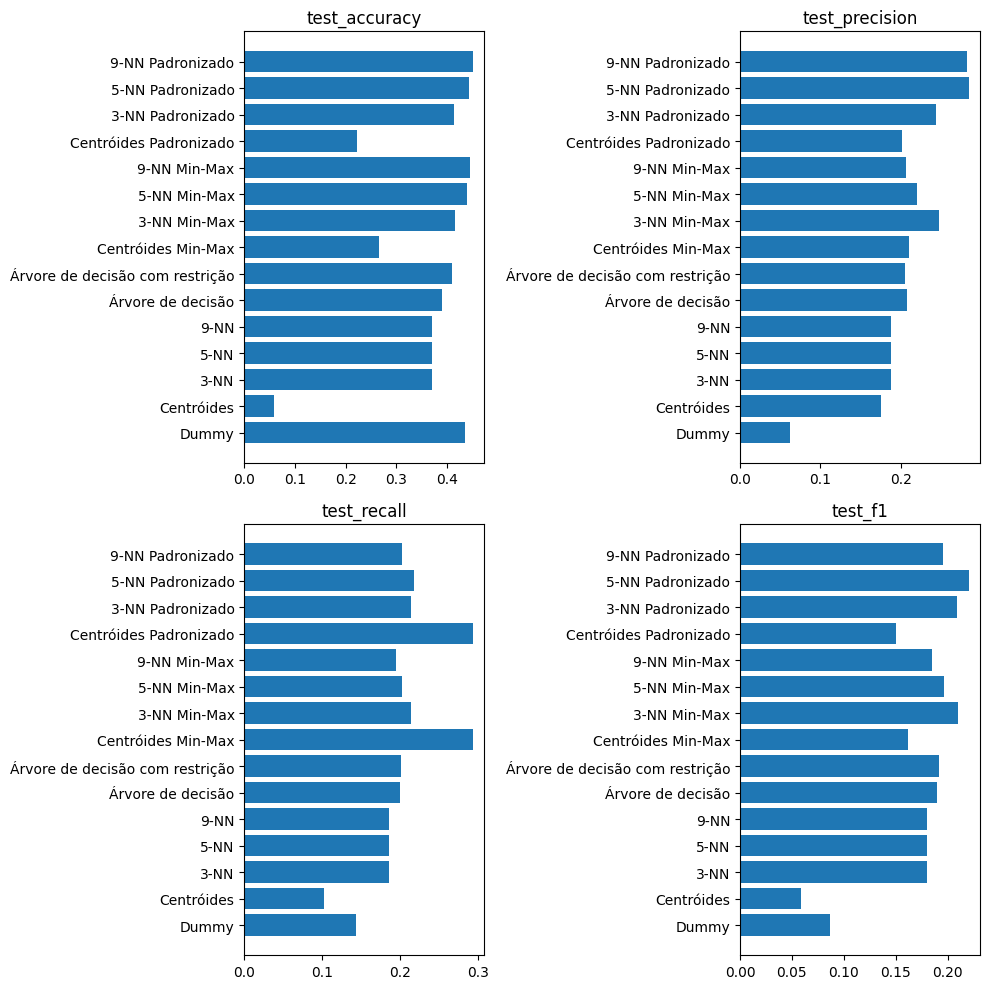

In [13]:
# um gráfico de barra para cada métrica (acurácia, precisão, Sensibilidade, F1 Score) com o desempenho dae cada modelo
import matplotlib.pyplot as plt

metrics = ['test_accuracy', 'test_precision', 'test_recall', 'test_f1']

fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for i, metric in enumerate(metrics):
    row, col = i // 2, i % 2
    axs[row, col].barh(results_df.index, results_df[metric], label=metric)
    axs[row, col].set_title(metric)

plt.tight_layout()
plt.show()


## Melhor classificador: métricas por iteração


============================== PARTIÇÃO 1 ==============================

Relatório de Classificação:
              precision    recall  f1-score   support

           3       0.33      0.17      0.22         6
           4       0.27      0.14      0.18        43
           5       0.54      0.65      0.59       402
           6       0.58      0.59      0.58       597
           7       0.51      0.40      0.44       215
           8       0.20      0.08      0.12        36
           9       0.00      0.00      0.00         1

    accuracy                           0.55      1300
   macro avg       0.35      0.29      0.31      1300
weighted avg       0.53      0.55      0.53      1300



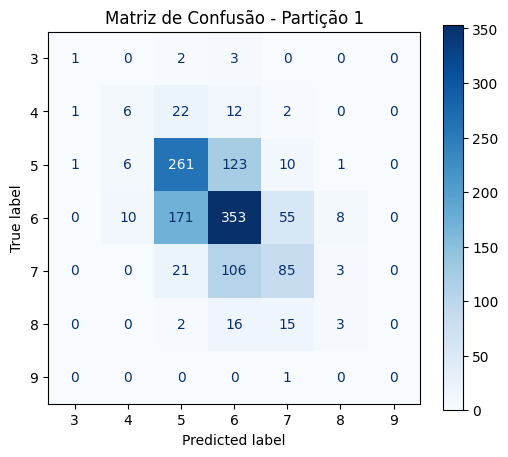


============================== PARTIÇÃO 2 ==============================

Relatório de Classificação:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         8
           4       0.29      0.13      0.18        53
           5       0.56      0.65      0.60       406
           6       0.58      0.59      0.59       587
           7       0.45      0.41      0.43       211
           8       0.45      0.14      0.22        35

    accuracy                           0.55      1300
   macro avg       0.39      0.32      0.34      1300
weighted avg       0.53      0.55      0.54      1300



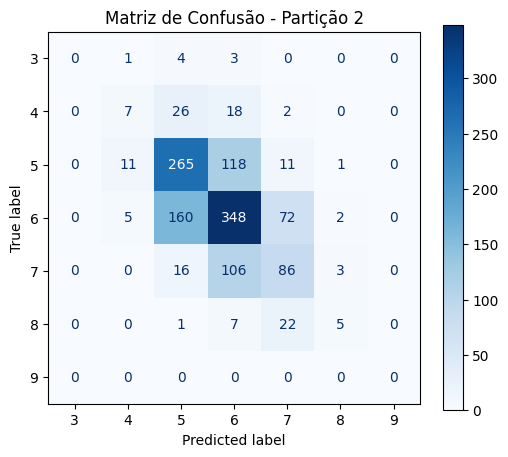


============================== PARTIÇÃO 3 ==============================

Relatório de Classificação:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         5
           4       0.16      0.09      0.12        33
           5       0.61      0.62      0.61       440
           6       0.54      0.63      0.58       549
           7       0.55      0.41      0.47       228
           8       0.50      0.12      0.19        42
           9       0.00      0.00      0.00         2

    accuracy                           0.56      1299
   macro avg       0.34      0.27      0.28      1299
weighted avg       0.55      0.56      0.55      1299



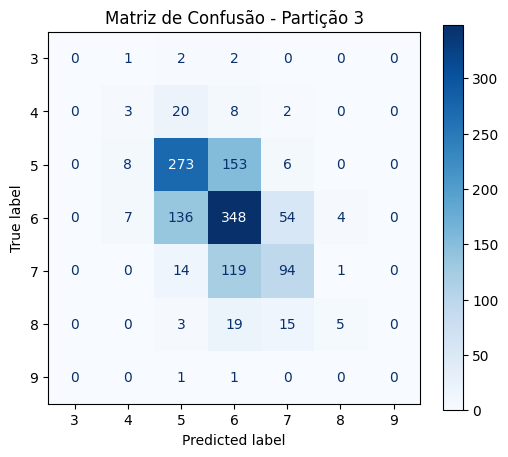


============================== PARTIÇÃO 4 ==============================

Relatório de Classificação:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         4
           4       0.13      0.05      0.07        43
           5       0.60      0.62      0.61       457
           6       0.53      0.62      0.57       536
           7       0.51      0.40      0.45       216
           8       0.44      0.10      0.16        41
           9       0.00      0.00      0.00         2

    accuracy                           0.55      1299
   macro avg       0.32      0.26      0.27      1299
weighted avg       0.53      0.55      0.53      1299



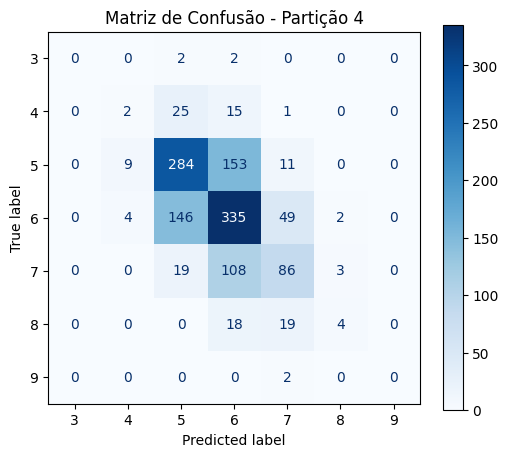


============================== PARTIÇÃO 5 ==============================

Relatório de Classificação:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         7
           4       0.22      0.11      0.15        44
           5       0.59      0.62      0.61       433
           6       0.59      0.64      0.61       567
           7       0.51      0.46      0.48       209
           8       0.33      0.18      0.23        39

    accuracy                           0.57      1299
   macro avg       0.37      0.34      0.35      1299
weighted avg       0.55      0.57      0.56      1299



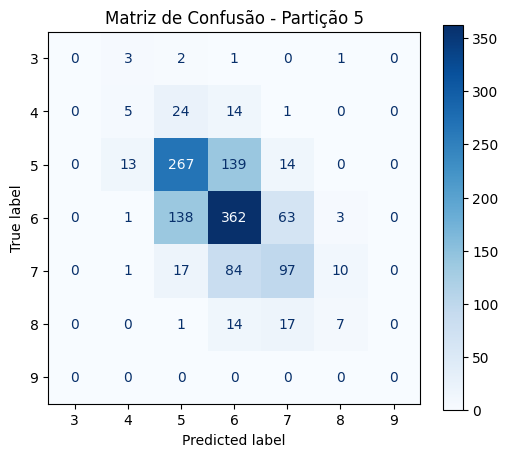

In [14]:
from sklearn.model_selection import KFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Configurações para a validação cruzada
kf = KFold(n_splits=5, shuffle=True, random_state=random_state)

# Pipeline para o 5-NN padronizado
pipeline_5nn = Pipeline(
    steps=[
        ('standard_scaler', StandardScaler()),
        ('classificador', KNeighborsClassifier(n_neighbors=5))
    ]
)

# Loop para treinar e avaliar em cada partição
for fold, (train_idx, test_idx) in enumerate(kf.split(X, y_np), 1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y_np.iloc[train_idx], y_np.iloc[test_idx]

    # Treinar o pipeline no conjunto de treino desta partição
    pipeline_5nn.fit(X_train, y_train)

    # Fazer predições no conjunto de teste desta partição
    y_pred = pipeline_5nn.predict(X_test)

    print(f"\n{'='*30} PARTIÇÃO {fold} {'='*30}")

    # Imprimir o classification report
    print("\nRelatório de Classificação:")
    print(classification_report(y_test, y_pred, zero_division=0))

    # Gerar e exibir a matriz de confusão para a partição
    cm = confusion_matrix(y_test, y_pred, labels=pipeline_5nn.classes_)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipeline_5nn.classes_)
    disp.plot(cmap='Blues', ax=ax, values_format='d')
    plt.title(f'Matriz de Confusão - Partição {fold}')
    plt.show()

## Atividade: Lidando com o Desbalanceamento de Classes

No dataset de vinhos analisado neste notebook, observamos um forte desbalanceamento de classes. Enquanto as notas intermediárias (5, 6 e 7) possuem milhares de exemplos, as classes extremas (3, 4, 8 e 9) possuem poucas amostras. Isso faz com que os classificadores tenham dificuldade em aprender os padrões dessas classes minoritárias, resultando em métricas de *Recall* e *F1-Score* muito baixas para elas.

Para tentar mitigar esse problema, você deve realizar uma atividade prática explorando duas abordagens comuns de reamostragem.

### Objetivos da Atividade
O objetivo é analisar o impacto de duas técnicas de sobreamostragem (*Oversampling*) no desempenho preditivo dos classificadores desenvolvidos.

### Estratégia A: Sobreamostragem por Replicação Aleatória (*Random Oversampling*)
Nesta estratégia simples, o objetivo é aumentar a representatividade das classes menos frequentes duplicando aleatoriamente amostras já existentes desse grupo até atingirem uma quantidade mais expressiva.

* **Como funciona:** Selecionam-se instâncias existentes das classes minoritárias e faz-se cópias exatas deles para adicionar ao conjunto de treinamento.
* **Vantagem:** Muito simples de implementar.
* **Desvantagem/Risco:** Pode induzir o modelo ao *overfitting* (sobreajuste), pois o classificador passará a ver múltiplas vezes exatamente as mesmas amostras, gerando fronteiras de decisão excessivamente específicas.

### Estratégia B: Sobreamostragem Sintética com SMOTE (*Synthetic Minority Over-sampling Technique*)
Em vez de apenas duplicar instâncias idênticas, a segunda estratégia propõe a criação de novos dados artificiais que sejam plausíveis e semelhantes aos originais, utilizando a técnica **SMOTE**.

* **O que é o SMOTE?** É um dos algoritmos de geração de dados sintéticos mais utilizados. Ele funciona encontrando os vizinhos mais próximos de instâncias da classe minoritária e desenhando uma linha reta entre eles. O SMOTE então gera uma nova amostra sintética em um ponto aleatório ao longo dessa linha.
* **Vantagem:** Evita o *overfitting* direto gerado pela cópia idêntica da Estratégia A, criando dados novos e ligeiramente variados, ampliando de forma mais suave a região de decisão das classes minoritárias.

### O que observar na análise final?
Após aplicar cada uma das estratégias no conjunto de treino e treinar os classificadores, você deve comparar as métricas obtidas via validação cruzada com o baseline original:
1. **Acurácia Geral:** Ela melhorou ou piorou? (Frequentemente a acurácia geral pode cair um pouco, pois o modelo deixa de focar apenas na classe majoritária).
2. **Macro F1-Score e Recall das Classes Minoritárias:** O modelo agora consegue identificar melhor os vinhos de qualidade 3, 4, 8 e 9?
3. **Matriz de Confusão:** Houve uma distribuição mais justa nas predições do modelo?

**OBSERVAÇÃO**: entregar a atividade como um notebook Jupyter ou Colab.